# 03 · Badminton — cechy, podobieństwo i proste modele
**Dane rzeczywiste:** cztery serie central/off-center z jednej rakiety, 46 automatycznych kandydatów.
To demonstracja narzędzi, nie pomiar skuteczności wykrywania wad ceramiki.

Wybierz kernel `.venv` / Ping Lab i **Run All**. Ten notebook działa samodzielnie;
nie musisz wcześniej uruchamiać pozostałych. Granice serii i zapowiedzi pochodzą
z `data/raw/badminton/session.json`. `project.json` pozostaje konfiguracją oryginalnych notebooków.
Nowe wyniki trafiają do osobnego katalogu; nagranie źródłowe pozostaje bez zmian.


In [1]:
NOTEBOOK = '03_cechy_i_modele'
from pathlib import Path
import sys, json, hashlib, io, base64
from datetime import datetime
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/pinglab').is_dir()), None)
assert ROOT is not None, 'Otwórz notebook z folderu projektu ceramic-ping-lab.'
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT/'scripts'))
%matplotlib inline
cfg = json.loads((ROOT/'data/raw/badminton/session.json').read_text())
SOURCE = ROOT/'data/raw/badminton'/cfg['audio']
assert SOURCE.is_file(), 'Brak nagrania badminton: nie przełączamy się automatycznie na demo.'
OUT = ROOT/'reports/runs/badminton-notebooks'/NOTEBOOK/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf
from scipy.signal import welch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Audio, HTML, Markdown
from pinglab.audio import load_audio, Config
from pinglab.recorder import segment_ringdown, ringdown_plot
from pinglab.features import extract_features, feature_columns, decay_curve
from pinglab.learning import make_classifier
from pinglab.series import evaluate_series, paired_folds
from pinglab.embeddings import ASTEncoder
from pinglab.robustness import mix_noise

RUN_AST = False
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
colors = {'central':'#137f83', 'offcenter':'#c56838'}
r = load_audio(SOURCE, Config(sr=48000, max_seconds=180))
print('Plik:', SOURCE.name, '| SHA256:', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(pd.DataFrame([r.qc]).drop(columns=['warnings']))
print('Uwagi QC:', r.qc['warnings'] or 'brak')

Plik: session.wav | SHA256: afc2d308b32b80ead3f80f795707a2059d2e359a33a2d6c20470464d41df7f07


,duration_s,native_sr,channels,selected_channel,peak_dbfs,rms_dbfs,clipping_fraction,dc_offset
0,88.99771,44100,1,0,-17.976912,-45.595115,0.0,8.182004e-09


Uwagi QC: ['Pasmo źródłowe kończy się przy 22050 Hz; resampling go nie odzyska']


## Przygotowanie uderzeń
Ten sam detektor i okna: 25 ms przed + 350 ms po początku, skrócone przed kolejnym zdarzeniem. Etykieta pochodzi z serii. Zdarzenie około 77 s pozostaje niepewne.

In [2]:
rows=[]; clips={}; series_traces={}
for s in cfg['series']:
 z=r.y[int(s['start_s']*r.sr):int(s['end_s']*r.sr)]
 tab,t,db=segment_ringdown(z,r.sr,**cfg['detector'])
 series_traces[s['series_id']]=(z,tab,t,db)
 interactive=ringdown_plot(z,r.sr,tab,t,db)
 interactive.write_html(OUT/(s['series_id']+'_segmentacja.html'),include_plotlyjs=True)
 for k,row in enumerate(tab.itertuples()):
  onset=float(row.onset_s);absolute=s['start_s']+onset
  a=max(0,onset-cfg['pre_s'])
  nxt=float(tab.iloc[k+1].onset_s) if k+1<len(tab) else len(z)/r.sr
  b=min(onset+cfg['feature_tail_s'],nxt-.015,len(z)/r.sr)
  clip=z[int(a*r.sr):int(b*r.sr)]
  eid=f"{s['series_id']}_{k+1:02d}"
  clips[eid]=clip
  uncertain=any(abs(absolute-v)<.05 for v in cfg['uncertain_onsets_s'])
  rows.append(dict(event_id=eid,series_id=s['series_id'],round=s['round'],label=s['label'],
   onset_s=absolute,offset_s=onset-a,window_s=len(clip)/r.sr,
   ringdown_s=row.duration_s,ringdown_status=row.status,uncertain=uncertain,
   peak_dbfs=20*np.log10(max(abs(clip).max(),1e-12)),
   **extract_features(clip,r.sr,onset-a,cfg['fmax'])))
events=pd.DataFrame(rows)
events.to_csv(OUT/'features.csv',index=False)
display(events.groupby(['series_id','label'],sort=False).agg(uderzenia=('event_id','size'),
 szczyt_mediana_dbfs=('peak_dbfs','median'),niepewne=('uncertain','sum')))
display(events[['event_id','onset_s','ringdown_s','ringdown_status','uncertain']])
assert all(not (a<=v<=b) for v in events.onset_s for a,b in cfg['speech_excluded_s'])
assert events.window_s.min()>.05

,,uderzenia,szczyt_mediana_dbfs,niepewne
series_id,label,,,
central_1,central,14,-26.799461,0
offcenter_1,offcenter,12,-34.025085,0
central_2,central,10,-31.644835,0
offcenter_2,offcenter,10,-31.444176,1


,event_id,onset_s,ringdown_s,ringdown_status,uncertain
0,central_1_01,8.525,0.070,zanik zaobserwowany,False
1,central_1_02,9.670,0.100,zanik zaobserwowany,False
2,central_1_03,10.860,0.140,zanik zaobserwowany,False
3,central_1_04,11.885,0.315,zanik zaobserwowany,False
4,central_1_05,12.945,0.170,zanik zaobserwowany,False
5,central_1_06,14.110,1.055,kolejne uderzenie przed zanikiem,False
6,central_1_07,15.165,0.570,zanik zaobserwowany,False
7,central_1_08,16.300,0.215,zanik zaobserwowany,False
8,central_1_09,17.385,0.120,zanik zaobserwowany,False
9,central_1_10,18.610,0.115,zanik zaobserwowany,False


## 4. Reprezentacja cech
Porównujemy rezonans (3 cechy), cechy fizyczne (15), MFCC i mel. Amplituda jest normalizowana przed ekstrakcją; osobno sprawdzamy, ile można odgadnąć z samej głośności.
PCA poniżej służy tylko do oglądania danych. Zostało dopasowane do wszystkich punktów i **nie jest testem skuteczności**. Kształt punktu oznacza rundę.


peak_hz         centroid_hz         decay10_s        peak_dbfs  \
             median     std      median     std    median   std     median   
series_id                                                                    
central_1    890.62  310.10      962.14  270.53      0.03  0.01 -26.799999   
central_2    890.62  244.58     1298.40  511.77      0.04  0.01 -31.639999   
offcenter_1  380.86  439.71     1349.17  244.15      0.04  0.02 -34.029999   
offcenter_2  638.67  553.61     1323.38  581.23      0.04  0.01 -31.440001   

                   
              std  
series_id          
central_1    2.62  
central_2    2.24  
offcenter_1  3.33  
offcenter_2  6.03

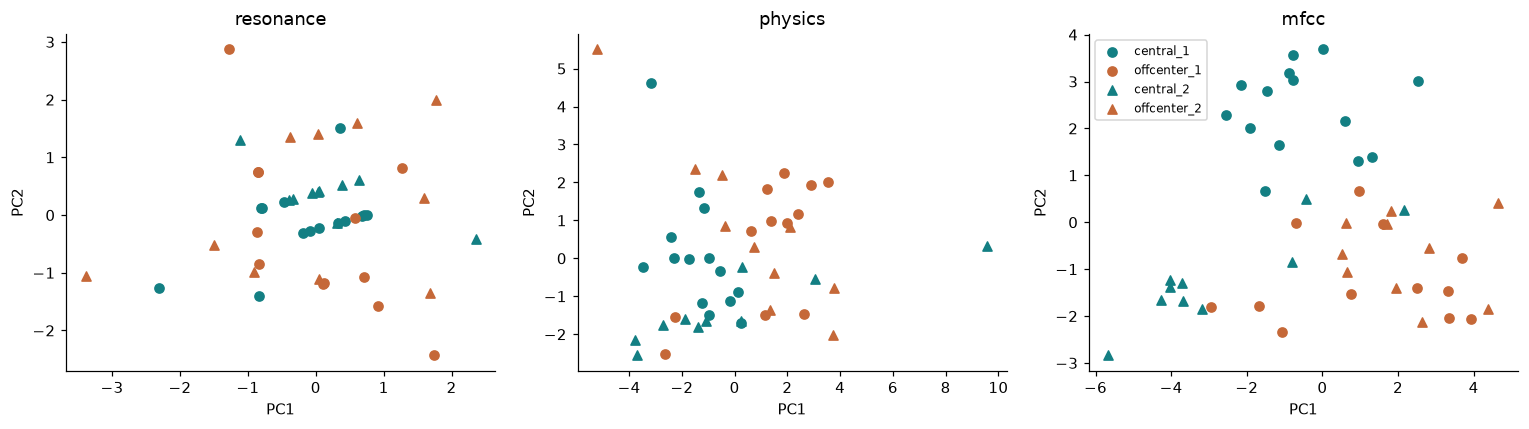

In [3]:
display(events.groupby('series_id')[['peak_hz','centroid_hz','decay10_s','peak_dbfs']].agg(['median','std']).round(2))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,family in zip(axes,['resonance','physics','mfcc']):
 x=StandardScaler().fit_transform(events[feature_columns(events,family)])
 xy=PCA(2).fit_transform(x)
 for s in cfg['series']:
  mask=events.series_id==s['series_id']
  ax.scatter(xy[mask,0],xy[mask,1],label=s['series_id'],c=colors[s['label']],marker='o' if s['round']==1 else '^')
 ax.set(title=family,xlabel='PC1',ylabel='PC2')
axes[-1].legend(fontsize=8);plt.tight_layout();plt.show()

## 5. Klasyfikacja i odległość od centralnych wzorców
Dwie próby: uczymy na seriach 1–2 i sprawdzamy 3–4, potem odwrotnie. Skalowanie i model uczą się tylko na części treningowej. Używamy ustalonej regresji logistycznej (`C=0.1`), bez poszukiwania najlepszego parametru.

Odległość pyta: „jak daleko ten dźwięk leży od centralnych uderzeń treningowych?”. Próg pochodzi wyłącznie z odległości między wzorcami treningowymi, ale nie jest skalibrowany. AUC ocenia kolejność wyników bez progu; balanced accuracy uśrednia trafność obu klas.

**Dwie rundy jednej sesji nie wystarczają do wiarygodnej oceny generalizacji.** Uderzenia są skorelowane; nie liczymy przedziałów ufności tak, jakby były niezależnymi obiektami. Porównanie wielu metod jest eksploracyjne.


,fold,train_series,test_series
0,1,"[central_2, offcenter_2]","[central_1, offcenter_1]"
1,2,"[central_1, offcenter_1]","[central_2, offcenter_2]"


,family,method,test_round,n_test,balanced_accuracy,auc,central_recall,offcenter_recall
0,loudness,logistic,1,26,0.161,0.048,0.071,0.250
1,loudness,logistic,2,20,0.400,0.470,0.200,0.600
2,resonance,logistic,1,26,0.286,0.185,0.071,0.500
3,resonance,logistic,2,20,0.450,0.470,0.400,0.500
4,resonance,distance,1,26,0.500,0.804,1.000,0.000
5,resonance,distance,2,20,0.450,0.630,0.900,0.000
6,physics,logistic,1,26,0.482,0.470,0.214,0.750
7,physics,logistic,2,20,0.550,0.570,0.400,0.700
8,physics,distance,1,26,0.512,0.583,0.857,0.167
9,physics,distance,2,20,0.550,0.690,0.800,0.300


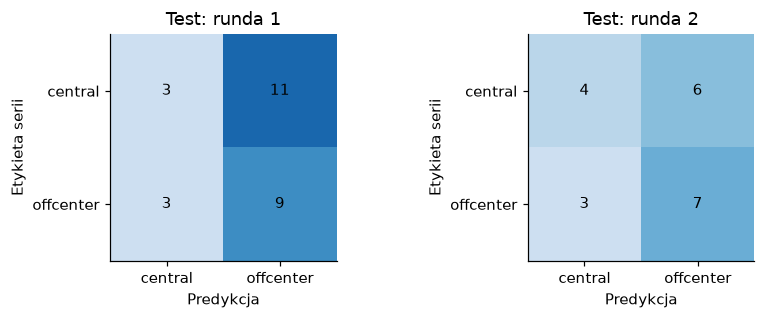

,event_id,series_id,label,fold,family,method,score,threshold,prediction,onset_s,uncertain
0,central_1_01,central_1,central,1,physics,logistic,0.565443,0.5,offcenter,8.525,False
1,central_1_02,central_1,central,1,physics,logistic,0.637992,0.5,offcenter,9.670,False
2,central_1_03,central_1,central,1,physics,logistic,0.512763,0.5,offcenter,10.860,False
3,central_1_05,central_1,central,1,physics,logistic,0.642296,0.5,offcenter,12.945,False
4,central_1_06,central_1,central,1,physics,logistic,0.624368,0.5,offcenter,14.110,False
5,central_1_07,central_1,central,1,physics,logistic,0.580101,0.5,offcenter,15.165,False
6,central_1_08,central_1,central,1,physics,logistic,0.572858,0.5,offcenter,16.300,False
7,central_1_09,central_1,central,1,physics,logistic,0.612724,0.5,offcenter,17.385,False
8,central_1_12,central_1,central,1,physics,logistic,0.714799,0.5,offcenter,21.020,False
9,central_1_13,central_1,central,1,physics,logistic,0.606400,0.5,offcenter,22.190,False


In [4]:
metrics=[];predictions=[]
for family in ['loudness','resonance','physics','mfcc','mel']:
 for method in (['logistic'] if family=='loudness' else ['logistic','distance']):
  m,p,audit=evaluate_series(events,family,method)
  metrics.append(m);predictions.append(p)
(OUT/'fold_audit.json').write_text(json.dumps(audit,indent=2))
display(pd.DataFrame(audit))
metrics=pd.concat(metrics,ignore_index=True);predictions=pd.concat(predictions,ignore_index=True)
display(metrics[['family','method','test_round','n_test','balanced_accuracy','auc','central_recall','offcenter_recall']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,row in zip(axes,metrics.query("family=='physics' and method=='logistic'").itertuples()):
 cm=np.array(row.confusion_matrix);ax.imshow(cm,cmap='Blues',vmin=0,vmax=14)
 for i in range(2):
  for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
 ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['central','offcenter'],yticklabels=['central','offcenter'],xlabel='Predykcja',ylabel='Etykieta serii',title=f'Test: runda {row.test_round}')
plt.tight_layout();plt.show()
errors=predictions.query("family=='physics' and method=='logistic' and label!=prediction")
display(errors.merge(events[['event_id','onset_s','uncertain']],on='event_id'))

## Które uderzenia są podobne?
Macierz odległości na wybranych cechach. To widok opisowy całego zbioru; skalowanie tutaj nie jest wykorzystywane do oceny modelu powyżej.

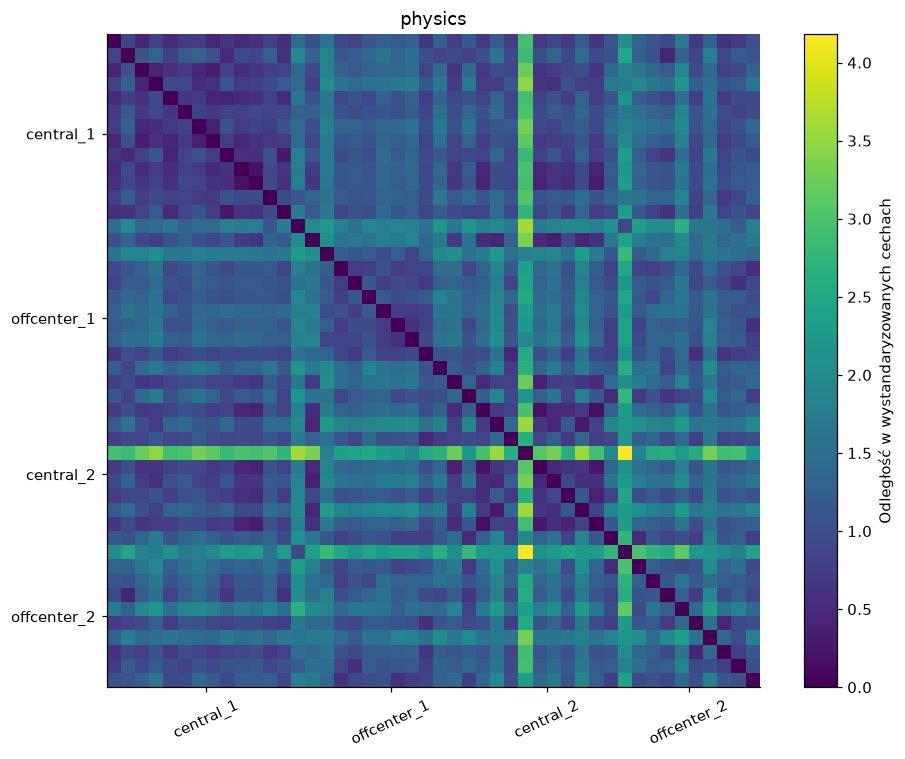

In [5]:
from scipy.spatial.distance import cdist
FAMILY='physics'
cols=feature_columns(events,FAMILY)
z=StandardScaler().fit_transform(events[cols])
d=cdist(z,z)/np.sqrt(len(cols))
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(d,cmap='viridis');fig.colorbar(im,ax=ax,label='Odległość w wystandaryzowanych cechach')
starts=events.groupby('series_id',sort=False).size()
centers=np.cumsum(starts)-starts/2-.5
ax.set(xticks=centers,yticks=centers,xticklabels=starts.index,yticklabels=starts.index,title=FAMILY)
plt.xticks(rotation=25);plt.tight_layout();plt.show()


**Granica interpretacji:** można ocenić przenoszenie między rundami tej samej rakiety. Test niezależnych detali i test nowej sesji są tutaj niemożliwe; nie tworzymy fikcyjnych plate_id.

In [6]:
print('GOTOWE:', NOTEBOOK, '| pliki wynikowe:', OUT)

GOTOWE: 03_cechy_i_modele | pliki wynikowe: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/badminton-notebooks/03_cechy_i_modele/20260928_144904_205358
